# <font color='lightblue'>Flagging Likely-Malignant Breast Masses with Logistic Regression</font>

**By:** Kashif Shafi, Regan Todd, Naveen Anend

**Dataset:** Breast Cancer Wisconsin (Diagnostic) Data Set — Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1993). UCI Machine Learning Repository. https://doi.org/10.24432/C5DW2B

**Course:** DATA 601: Working With Data and Visualization, Master of Data Science and Analytics, University of Calgary (Fall 2026)

**Data Set up and Imports:**

In [1]:
!pip install -q ucimlrepo
from ucimlrepo import fetch_ucirepo

import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score

In [2]:
breast_cancer = fetch_ucirepo(id=17)

breast_cancer_df = pd.concat([breast_cancer.data.features, breast_cancer.data.targets],axis=1)

breast_cancer_df = breast_cancer_df[["Diagnosis"] +[col for col in breast_cancer_df.columns if col.endswith("1")]]

display(breast_cancer_df.head())

,Diagnosis,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883


## <font color='lightblue'>1. The question </font>

**Question**

Can a computational model be used to determine whether a breast tissue sample is malignant or benign based on cell nucleus measurements? 

The ideal outcome of this analysis is a Logistic Regression Model that, on tumours it has never seen before, (1) catches as many malignant tumours as possible (high recall), since missing a cancer is much more serious than a false alarm, (2) is accurate overall and clearly beats the 63% we would get by always guessing benign, and (3) is easy to interpret, so we can see which of the 10 physical variables push a prediction towards malignant.

**Data source**

We will use the UCI Machine Learning Repository's Breast Cancer Wisconsin (Diagnostic) data set. 

Accuracy: Each value in the data set is an average of all the nuclei in a sample, so one unusual nucleus will not change the result much. However, the measurements depend on how the outline of each nucleus was traced on the image, so small differences in tracing or image quality could change values like area or concavity. Sample selection is also something to consider. All of the samples come from one clinic in the early 1990s, and every patient already had a lump that needed testing, so the results may not be the same for other hospitals or patient groups.

**Type of problem and model**

This is supervised, binary classification: every sample has a known label (malignant or benign), and there are exactly two classes. We use logistic regression because it is a suitable method for binary classification and estimates the probability that a tumour is malignant based on its measurements. It also allows us to interpret the coefficients to understand how different features relate to the predicted diagnosis.

## <font color='lightblue'>2. Data understanding, exploration, and visualization </font>

The data set uses digitally imaged cell nucleus measurements from individual breast biopsies. Based on all of these features, a model can be created to predict if a tumour is malignant (cancerous) or benign (non cancerous). 

**Summary of Variables used in the Model**

- **Radius:** mean distance from the centre to points on the perimeter
- **Texture:** a measure of how much the shades of gray in the nuclei image vary
- **Perimeter:** the length of the nucleus boundary
- **Area:** the size of the nucleus
- **Smoothness:** variation in the radius lengths
- **Compactness:** (perimeter)² / area − 1.0
- **Concavity:** severity of indented portions of the nuclei
- **Concave points:** number of concave portions on the boundary of each nucleus
- **Symmetry:** how symmetric the nucleus shape is
- **Fractal Dimension:** roughness of the boundary of the nuclei

**Visualizing Tumour Diagnosis:**

Since we are attempting to model tumour diagnosis as a result of the 10 numerical variables, it is useful to visualize the malignant and benign tumour proportions in our sample. The visualization shows that benign tumours make up a larger proportion of the dataset (62.74%) than malignant tumours (37.26%). This is important to recognize because the two diagnosis groups are not equally represented in our data. Understanding the distribution of the outcome variable provides context and helps us interpret the results of our model.

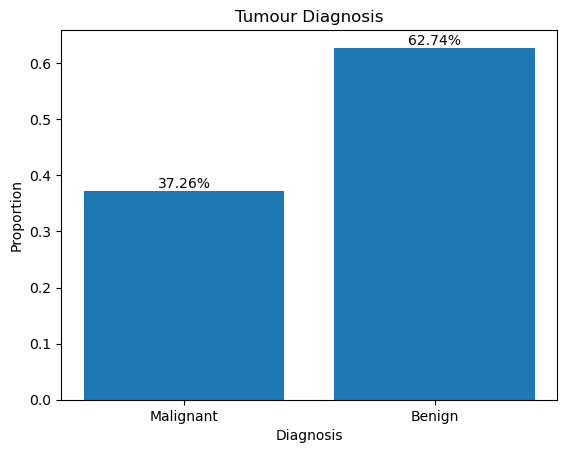

In [3]:
prop_malignant = (breast_cancer_df["Diagnosis"] == "M").mean()
prop_benign = (breast_cancer_df["Diagnosis"] == "B").mean()

plt.bar(["Malignant", "Benign"], [prop_malignant, prop_benign])

plt.text(0, prop_malignant, f"{prop_malignant:.2%}", ha="center", va="bottom")
plt.text(1, prop_benign, f"{prop_benign:.2%}", ha="center", va="bottom")

plt.xlabel("Diagnosis")
plt.ylabel("Proportion")
plt.title("Tumour Diagnosis")
plt.show()

**Figure 1:** proportion of malignant and benign tumours in the sample data. (n=569)

**Summary Statistics by Diagnosis:**

To get a better idea of how the two groups differ, we looked at the mean, median, and standard deviation of some of the key variables for malignant and benign tumours.

In [4]:
key_vars = ["concave_points1", "concavity1", "area1", "texture1", "smoothness1", "compactness1"]

breast_cancer_df.groupby("Diagnosis")[key_vars].agg(["mean", "median", "std"]).T.round(3)

Diagnosis                     B        M
concave_points1 mean      0.026    0.088
                median    0.023    0.086
                std       0.016    0.034
concavity1      mean      0.046    0.161
                median    0.037    0.151
                std       0.043    0.075
area1           mean    462.790  978.376
                median  458.400  932.000
                std     134.287  367.938
texture1        mean     17.915   21.605
                median   17.390   21.460
                std       3.995    3.779
smoothness1     mean      0.092    0.103
                median    0.091    0.102
                std       0.013    0.013
compactness1    mean      0.080    0.145
                median    0.075    0.132
                std       0.034    0.054

**Table 1:** summary statistics of key variables by diagnosis (M = malignant, B = benign).

Malignant tumours have much bigger nuclei, with an average area of about 978 compared to about 463 for benign tumours, so roughly twice as large. They also have more than three times as many concave points (0.088 vs 0.026) and about 3.5 times the concavity (0.161 vs 0.046), which means the outline of the nucleus is a lot more irregular. Texture is higher in malignant tumours too (21.6 vs 17.9), so the shading varies more. The raw gap in smoothness looks small (0.103 vs 0.092), but both groups have an SD of only 0.013, so the gap is close to one standard deviation, which is not small. Based on this, we expect concave points, concavity, area, texture, and smoothness to push the model towards predicting malignant.

**Visualizing Key Variables per Tumour Diagnosis:**

Concavity is a measure of irregularity in the outer boundary of a nucleus. From the visualization below, we can see that on average, benign tumours have lower concavity scores, and malignant tumours have higher concavity scores. This is helpful for understanding the relationship between concavity and tumour diagnosis and provides context. We also plotted concave points, area, and texture, since these are the variables that stood out in Table 1.

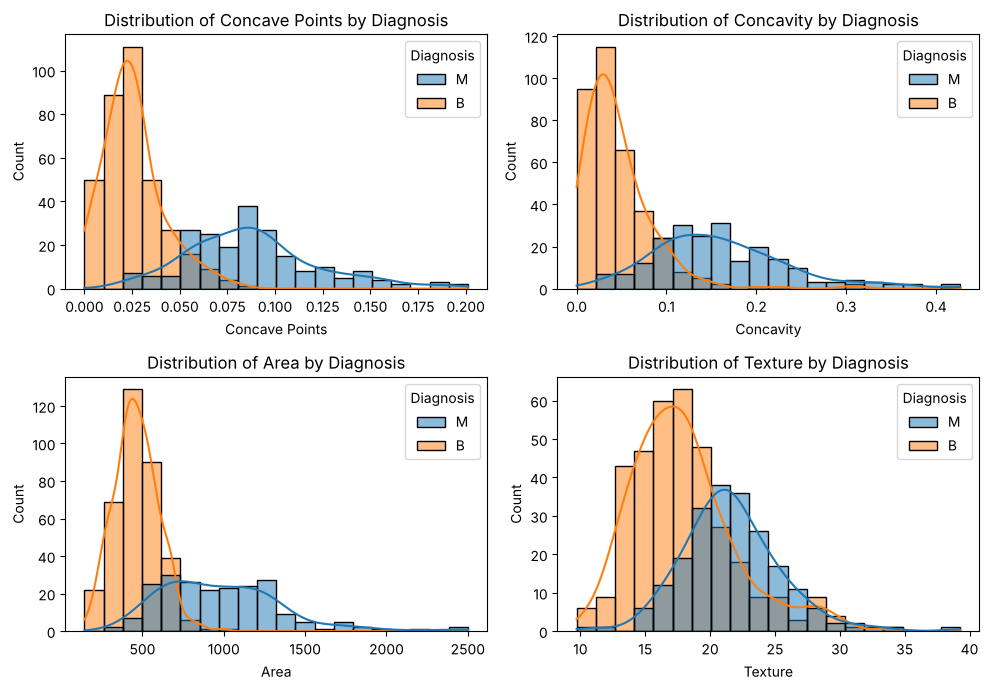

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

plot_vars = [("concave_points1", "Concave Points"), ("concavity1", "Concavity"), ("area1", "Area"), ("texture1", "Texture")]

for ax, (col, label) in zip(axes.ravel(), plot_vars):
    sns.histplot(data=breast_cancer_df, x=col, hue="Diagnosis", bins=20, kde=True, ax=ax)
    ax.set_xlabel(label)
    ax.set_ylabel("Count")
    ax.set_title(f"Distribution of {label} by Diagnosis")

plt.tight_layout()
plt.show()

**Figure 2.** The distribution of concave points, concavity, area, and texture for each diagnosis. For all four variables, malignant samples (blue) are shifted to the right of benign samples (orange). Concave points shows the clearest split between the two groups, while texture overlaps the most. There is a zone of overlap in the middle of each plot, which is where a model will make its mistakes.

Lastly, to visualize what variables are correlated in the data set, we created a heatmap. Highly correlated variables provide very similar information to the model. This might make it hard for the model to predict individual effects of each variable on the outcome. 

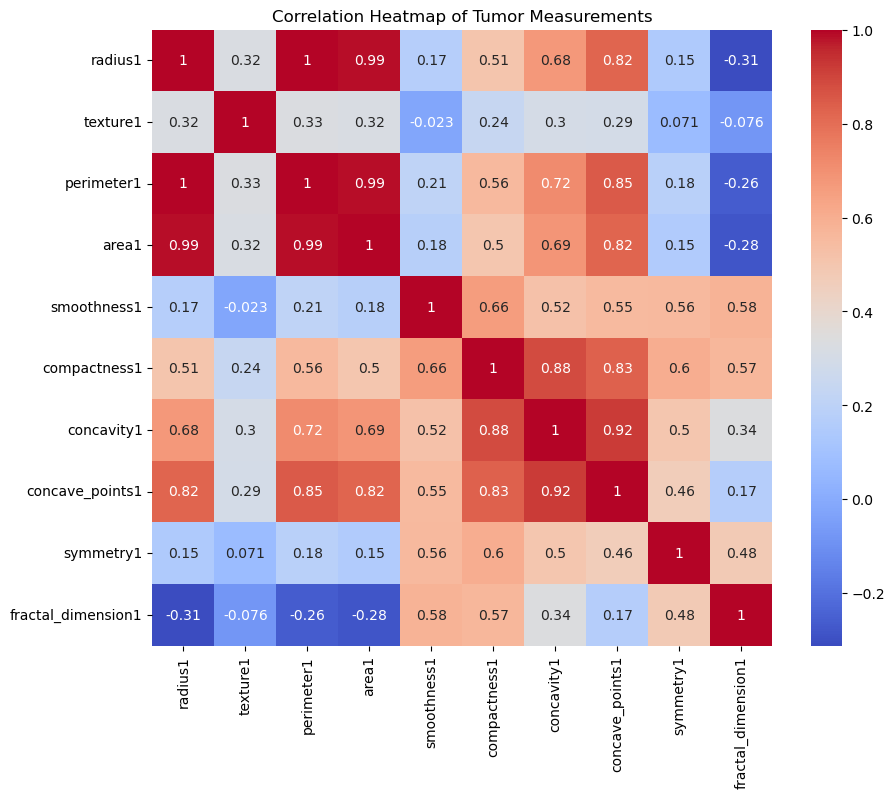

In [6]:
correlation = breast_cancer_df.drop(columns="Diagnosis").corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation,annot=True,cmap="coolwarm")

plt.title("Correlation Heatmap of Tumor Measurements")
plt.show()

**Figure 3:** heatmap correlations of the 10 numeric variables from the data set. As expected, perimeter, area, and radius are all almost perfectly correlated, which might make it difficult for logistic regression to separate their individual effects on the diagnosis.

The heatmap is useful to help us understand the relationships between the predictor variables. For example, concavity and concave points (0.92), concavity and compactness (0.88), and smoothness and compactness (0.66) show relatively strong correlations. These relationships are important to consider when interpreting the model's coefficients, since correlated features can make it harder to determine the individual contribution of each variable

## <font color='lightblue'>3. Data wrangling and preprocessing </font>

**Selecting the features:** When we loaded the data, we only kept the diagnosis and the 10 mean variables (the columns ending in "1") and left out the 20 standard error and "worst" columns. Those columns describe the same 10 characteristics, so they would mostly add more overlap between the variables (see Figure 3). Keeping one value per characteristic also makes the model easier to explain.

In [7]:
print("Rows, columns:", breast_cancer_df.shape)
print("Variables used:", list(breast_cancer_df.columns.drop("Diagnosis")))

Rows, columns: (569, 11)
Variables used: ['radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1', 'compactness1', 'concavity1', 'concave_points1', 'symmetry1', 'fractal_dimension1']


**Step 1:** Check for missing values 

Having missing values in the dataset can cause the model to return an error or affect its ability to make accurate predictions. The model relies on the available values to identify patterns in the data, so missing values can make it difficult for the model to use certain observations properly. Therefore, it is important to check for missing values before beginning the analysis. There are no missing values in our data set that we need to deal with. 

In [8]:
print("Missing Values:", breast_cancer_df.isna().sum().sum())

Missing Values: 0


**Step 2:** Convert Diagnosis to 1/0 

The model requires a numeric target variable in order to perform the calculations required. By encoding the diagnosis as 0/1 (for benign/malignant), we are turning the variable into a format that the model can use.

In [9]:
breast_cancer_df["Diagnosis"] = LabelEncoder().fit_transform(breast_cancer_df["Diagnosis"])
print("Encoding Done")

Encoding Done


**Step 3:** Create the Train/Test Split

To build a model, we need to split the data into training and testing data. 

Training data is used first to teach the model the patterns in the data. The training data will be used to teach the model the patterns between the 10 measurements and tumour diagnosis. 

The testing data is then used to see if the model performs well on data that it has never seen before. This way, we can evaluate how well the model makes predictions.  

We use an 80/20 split because it provides a good balance between giving the model enough data to learn from while still keeping enough observations to evaluate its performance on unseen data. With 569 observations, approximately 455 observations are used for training and 114 are used for testing.

stratify = y makes sure the training and testing datasets have approximately the same proportion of benign and malignant tumours as the original dataset.

random_state = 42 makes sure the results are reproducible.

In [10]:
X = breast_cancer_df.drop(columns="Diagnosis")
y = breast_cancer_df["Diagnosis"]

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training and Test Data Created")

Training and Test Data Created


**Step 4:** completing 5-fold cross-validation

This helps us test how the model will perform on different subsets of the data. Through 5-fold cross validation, the training data is split further into 5 groups, where one of these groups acts as test data and the other four act as training data. The cycle repeats 5 times and an average accuracy is calculated across all five tests. Inside each fold, the data is scaled using only that fold’s training data, so the validation data does not leak into the training.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = []

for train_index, val_index in cv.split(x_train, y_train):

    x_fold_train = x_train.iloc[train_index]
    x_fold_val = x_train.iloc[val_index]

    y_fold_train = y_train.iloc[train_index]
    y_fold_val = y_train.iloc[val_index]

    scaler = StandardScaler()
    x_fold_train = scaler.fit_transform(x_fold_train)
    x_fold_val = scaler.transform(x_fold_val)

    model = LogisticRegression()
    model.fit(x_fold_train, y_fold_train)

    y_fold_pred = model.predict(x_fold_val)
    scores.append(accuracy_score(y_fold_val, y_fold_pred))

print("Cross-validation accuracies:", [round(s, 3) for s in scores])
print("Mean cross-validation accuracy:", round(sum(scores) / len(scores), 3))

Cross-validation accuracies: [0.923, 0.956, 0.934, 0.934, 0.956]
Mean cross-validation accuracy: 0.941


**Step 5:** Scale all numeric variables 

To make sure that certain variables do not have a disproportionately large influence on the model, all the numerical variables are scaled. Measurements like area will naturally have larger values than radius due to the nature of the measurement. By scaling the measurements, all of the variables are placed on a similar scale, which helps the logistic regression model estimate the effects of each variable more effectively.

In [12]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

print("Variables Scaled")

Variables Scaled


## <font color='lightblue'>4. Build and test the model</font>



Our question is: can digitally imaged cell-nucleus measurements be used to determine whether a breast tissue sample is benign or malignant? 

To test this, we give the model our training data, which contains the Y variable "Diagnosis" and the 10 scaled X variables. The model will use the variables and the diagnosis to learn a pattern.

We use scikit-learn's default settings for logistic regression (the lbfgs solver with L2 regularization, C = 1). These are appropriate here because the variables are already scaled, the data set is small with only 10 variables, and the mild regularization helps keep the coefficients stable when variables like radius, perimeter, and area are highly correlated.

In [13]:
model = LogisticRegression()

model.fit(x_train, y_train)

print("Model Created")


Model Created


To measure the performance of our model, we use precision, accuracy, and recall. 

**Precision:** how many of the predicted positives (malignant diagnoses) are actually positive

**Accuracy:** how many of all of the predictions are correct

**Recall:** of the true positives (malignant diagnoses), how many did the model correctly predict? 

We can visualize these using a confusion matrix. 

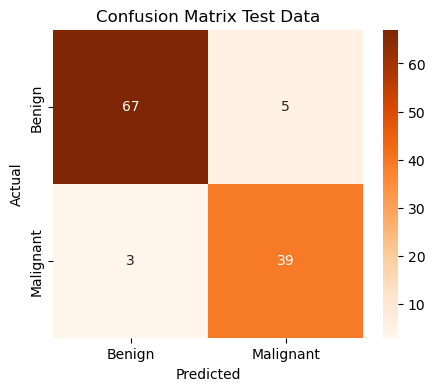

In [14]:
y_pred = model.predict(x_test)

plt.figure(figsize=(5,4))
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.title("Confusion Matrix Test Data")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**Figure 4:** confusion matrix of the model's predictions on the test data (n=114).

Based on the Confusion Matrix, we can observe the following: 

- Precision: of 44 predicted malignant tumours, 39 were actually malignant, giving a precision of 88.64%
- Accuracy: of 114 total observations, the model correctly identified 106 of the tumours, giving an accuracy of 92.98%
- Recall: of the 42 truly malignant cases, the model correctly predicted 39 of them, giving a recall of 92.86%

The accuracy score, precision score, and recall score are also computed using functions below. 

In [15]:
train_accuracy = accuracy_score(y_train, model.predict(x_train))
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)


print("Accuracy:", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))
print("Train accuracy:", round(train_accuracy,3))

Accuracy: 0.93
Precision: 0.886
Recall: 0.929
Train accuracy: 0.941


Our model performs well because it correctly identifies most tumours and detects a high proportion of malignant cases. However, the three malignant tumours classified as benign are particularly important, since missing a malignant tumour could have serious consequences in a real-world setting.

The small difference between the training accuracy and the test accuracy suggests that the model is not significantly overfitting and can generalize well to new data.

If we were to use a baseline model that always predicts the most common diagnosis (benign), that would give us 63.16% accuracy. This is the accuracy we would get in our test set if it was predicted that every tumour is benign. There are 72 actually benign tumours in the test set and there are 114 observations in the test set, so 72/114 tumours have the correct predicted diagnosis. 


Our logistic regression model achieved an accuracy of 92.98%, compared with 63.16% accuracy when always predicting the majority class, Benign. This shows that our model performs substantially better than a baseline approach that ignores the numerical measurements and predicts every tumour as benign.

Additionally, considering the cross-validation accuracy score from earlier of 94.1%, this is very close to the test accuracy, which tells us that the model's performance is consistent across different data splits. This also makes our model more reliable, as it is clear that the model can perform accurately on different samples. The training accuracy also came out to 94.1%, but that is just a coincidence, since the two are calculated in different ways.

## <font color='lightblue'>5. Interpret the model</font>

To determine the most important features, we calculated the logistic regression coefficient of every variable. 


In [16]:
coefficients = model.coef_[0]

feature_impact = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': coefficients
})

feature_impact = feature_impact.sort_values(
    by='Coefficient', ascending=False
).round(3)

print(feature_impact)

              Feature  Coefficient
7     concave_points1        1.664
1            texture1        1.489
3               area1        1.231
4         smoothness1        1.145
0             radius1        1.045
2          perimeter1        0.911
6          concavity1        0.883
8           symmetry1        0.429
5        compactness1       -0.276
9  fractal_dimension1       -0.418


Since we scaled the variables, each coefficient tells us how much the log-odds of a tumour being malignant change when that variable goes up by one standard deviation, with the other variables staying the same. Because we used the default settings of scikit-learn’s LogisticRegression, which include L2 regularization (C = 1), the coefficients are also shrunk slightly towards zero. 

Taken one at a time, concave points, texture, and area had the largest coefficients. However, area, radius, and perimeter share one size effect that the model splits three ways. When area is kept as the only size variable (see the refit below), its coefficient is about 2.5, larger than any other, so once the size variables are combined, nucleus size is actually the strongest single predictor, followed by concave points and texture.

Positive coefficients indicate that higher feature values increase the predicted odds of a tumour being malignant, while negative coefficients indicate that they decrease the predicted odds. The magnitude and sign of each coefficient indicate the strength and direction of the feature's relationship with the model's predictions.

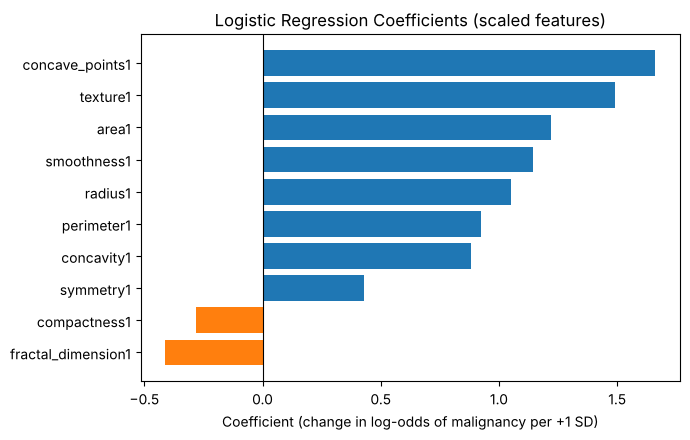

In [17]:
plot_df = feature_impact.sort_values(by="Coefficient")

plt.figure(figsize=(7, 4.5))
plt.barh(plot_df["Feature"], plot_df["Coefficient"], color=["tab:blue" if c > 0 else "tab:orange" for c in plot_df["Coefficient"]])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient (change in log-odds of malignancy per +1 SD)")
plt.title("Logistic Regression Coefficients (scaled features)")
plt.tight_layout()
plt.show()

**Figure 5:** logistic regression coefficients for each variable. Blue bars push the prediction towards malignant and orange bars push it towards benign.

- Concave points (1.664) and texture (1.489) have the largest coefficients, so nuclei with more indentations in their outline and more uneven shading are much more likely to be malignant. This matches what we saw in Table 1 and Figure 2.
- Area (1.231), radius (1.045), and perimeter (0.911) are all positive. Since these three are almost perfectly correlated, the model splits one "size" effect between them, so it makes more sense to read them together: bigger nuclei mean a higher chance of malignancy.
- Smoothness (1.145) also adds to the prediction. Its raw difference looks small (0.103 vs 0.092), but it is close to one standard deviation, so it separates the groups more than it seems.
- Compactness (-0.276) and fractal dimension (-0.418) are small and negative. Compactness overlaps strongly with concavity (0.88) and concave points (0.83), so there is not much new information left once those are in the model, and on its own it is actually higher in malignant tumours (Table 1). Fractal dimension is only weakly linked to concavity and concave points, but in Figure 3 it is linked to smoothness (0.58), compactness (0.57), and, negatively, to nucleus size (about -0.3). Its small negative value comes from these overlaps, so neither coefficient means the variable lowers the risk.
- These coefficients show associations, not causes.

To check the overlap between radius, perimeter, and area, we also refit the model without radius and perimeter, keeping area as the only size variable.

In [18]:
reduced_cols = [c for c in X.columns if c not in ["radius1", "perimeter1"]]
keep_idx = [list(X.columns).index(c) for c in reduced_cols]

reduced_model = LogisticRegression()
reduced_model.fit(x_train[:, keep_idx], y_train)
y_pred_reduced = reduced_model.predict(x_test[:, keep_idx])

print("Confusion matrix (without radius and perimeter):")
print(confusion_matrix(y_test, y_pred_reduced))
print("Accuracy:", round(accuracy_score(y_test, y_pred_reduced), 3))
print("Recall:", round(recall_score(y_test, y_pred_reduced), 3))
print(pd.DataFrame({"Feature": reduced_cols, "Coefficient": reduced_model.coef_[0]}).sort_values(by="Coefficient", ascending=False).round(3))

Confusion matrix (without radius and perimeter):
[[67  5]
 [ 3 39]]
Accuracy: 0.93
Recall: 0.929
              Feature  Coefficient
1               area1        2.509
5     concave_points1        1.978
0            texture1        1.410
2         smoothness1        1.037
4          concavity1        0.865
6           symmetry1        0.364
3        compactness1       -0.041
7  fractal_dimension1       -0.718


The results stay the same (same confusion matrix, 92.98% accuracy and 92.86% recall), and the coefficient for area goes up to about 2.5, the largest in the model and ahead of concave points (about 2.0). So once the size variables are combined, nucleus size is actually the strongest single predictor, and one size variable is enough.

## <font color='lightblue'>6. Answer and next steps</font>

The goal of this analysis was to determine if a Logistic Regression Model could predict if a breast tumour is malignant or benign based off of 10 physical variables. The model we created successfully identified 39/42 truly malignant tumours, giving a recall of 92.86%. The model had an overall accuracy of 92.98%, which is high compared to the baseline model where we predict that all tumours are benign (which gave 63.16% accuracy). 

However, it incorrectly classified three malignant tumours as benign, which is important to consider because missed malignant cases could have serious consequences. Overall, we partly achieved our goal. The model predicts tumour diagnoses with relatively high accuracy, but since it still missed three malignant tumours, the recall is not yet high enough for real clinical use. The main limitations are that all of the data comes from one clinic in the early 1990s, and that the test set is small, so each missed cancer changes the recall by about 2.4 percentage points. As a next step, we could lower the 0.5 probability threshold so the model flags more borderline tumours as malignant (choosing the new threshold with the training data, not the test set), test other classification models, investigate the overlap between highly correlated features such as radius, perimeter, and area, and evaluate the model on additional data to determine whether its performance remains consistent.